# VoltAhead — Final Model Selection and Test Evaluation

## 1. Objective

This notebook documents the final model selection
and evaluates the selected model on the held-out
test dataset.

The final model is selected exclusively based on
validation performance, using seen-station AP₀
as the primary selection metric.

The selected model configuration is frozen before
test evaluation.

No additional model training, hyperparameter tuning,
calibration, or threshold optimization is performed
using the test dataset.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import subprocess

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from preprocessing import FEATURE_COLUMNS

from evaluation import (
    validate_prediction_output,
    evaluate_predictions,
    evaluate_by_horizon,
    evaluate_by_station_group
)

DATA_DIR = ROOT / "data" / "processed"
MODEL_DIR = ROOT / "outputs" / "models"
TABLE_DIR = ROOT / "outputs" / "tables"
FIGURE_DIR = ROOT / "outputs" / "figures"
PREDICTION_DIR = ROOT / "outputs" / "predictions"

print("Project root:", ROOT)
print("Number of features:", len(FEATURE_COLUMNS))

Project root: /Users/nehiraydemir/VoltAhead
Number of features: 16


## 2. Final Model Selection

Random Forest Initial is selected as the final model
based on the cross-model validation comparison.

Selection rationale:

- Highest seen-station AP₀: 0.979618
- Lowest seen-station Brier score: 0.002755
- Highest AP₀ across all three evaluated prediction horizons
- Strong performance compared with persistence baselines

Both initial and optimized model versions were considered.

Although the optimized Random Forest achieves slightly
higher F1 and recall, the initial version performs better
on the predefined primary selection metric.

The held-out test dataset is not used for model selection.

In [12]:
MODEL_PATH = MODEL_DIR / "random_forest" / "initial_model.joblib"

assert MODEL_PATH.exists()
assert len(FEATURE_COLUMNS) == 16

final_config = {
    "dataset_version": "VOLTAHEAD-DATA-V1",
    "model_name": "random_forest",
    "model_version": "initial",
    "model_artifact": str(MODEL_PATH.relative_to(ROOT)),
    "artifact_sha256": hashlib.sha256(
        MODEL_PATH.read_bytes()
    ).hexdigest(),
    "primary_metric": "seen_station_ap_0",
    "validation_ap_0": 0.979618,
    "validation_brier_score": 0.002755,
    "threshold": 0.5,
    "calibration": None,
    "prediction_horizons": [30, 40, 60],
    "feature_columns": list(FEATURE_COLUMNS),
    "probability_definition": "P(Available=1)",
    "selection_split": "validation",
    "test_used_for_selection": False,
        "retraining": False,
    "git_commit": "611c8311cfe522fbac7be312bd6e5bf857444324"
}

print(json.dumps(final_config, indent=2))

{
  "dataset_version": "VOLTAHEAD-DATA-V1",
  "model_name": "random_forest",
  "model_version": "initial",
  "model_artifact": "outputs/models/random_forest/initial_model.joblib",
  "artifact_sha256": "59971b14c5354140658be2fff4f87f749283b831695e086a88aadd841fddb2b1",
  "primary_metric": "seen_station_ap_0",
  "validation_ap_0": 0.979618,
  "validation_brier_score": 0.002755,
  "threshold": 0.5,
  "calibration": null,
  "prediction_horizons": [
    30,
    40,
    60
  ],
  "feature_columns": [
    "station_id",
    "hour",
    "day_of_week",
    "is_weekend",
    "current_idle",
    "current_busy",
    "station_capacity",
    "occupancy_rate",
    "idle_lag_5",
    "idle_lag_10",
    "idle_lag_15",
    "idle_lag_30",
    "idle_lag_40",
    "idle_lag_60",
    "idle_lag_120",
    "prediction_horizon"
  ],
  "probability_definition": "P(Available=1)",
  "selection_split": "validation",
  "test_used_for_selection": false,
  "retraining": false,
  "git_commit": "611c8311cfe522fbac7be312bd6

In [13]:
TABLE_DIR.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = TABLE_DIR / "final_model_config.json"

if CONFIG_PATH.exists():
    saved_config = json.loads(CONFIG_PATH.read_text())
    assert saved_config == final_config, "Frozen configuration mismatch."
else:
    CONFIG_PATH.write_text(
        json.dumps(final_config, indent=2)
    )

print("Final model configuration frozen.")
print("Saved to:", CONFIG_PATH.relative_to(ROOT))

Final model configuration frozen.
Saved to: outputs/tables/final_model_config.json


## 3. Held-Out Test Dataset

The frozen Random Forest Initial model is evaluated
on the held-out test dataset covering January 14–21, 2023.

The test dataset has not been used for model training,
hyperparameter tuning, calibration, threshold selection,
or final model selection.

Seen and unseen stations are identified using station
IDs from the shared training dataset.

In [4]:
test = pd.read_parquet(DATA_DIR / "test.parquet")

training_station_ids = set(
    pd.read_parquet(
        DATA_DIR / "train.parquet",
        columns=["station_id"]
    )["station_id"].unique()
)

assert len(test) == 620433
assert test[FEATURE_COLUMNS].notna().all().all()
assert test["target"].isin([0, 1]).all()

print("Test observations:", len(test))
print("Test stations:", test["station_id"].nunique())
print("Test start:", test["time"].min())
print("Test end:", test["time"].max())

print(
    "Seen stations:",
    test.loc[
        test["station_id"].isin(training_station_ids),
        "station_id"
    ].nunique()
)

print(
    "Unseen stations:",
    sorted(
        set(test["station_id"].unique())
        - training_station_ids
    )
)

print("\nObservations by horizon:")
print(test["prediction_horizon"].value_counts().sort_index())

Test observations: 620433
Test stations: 93
Test start: 2023-01-14 00:00:00
Test end: 2023-01-21 23:25:00
Seen stations: 91
Unseen stations: [np.int32(1790), np.int32(1948)]

Observations by horizon:
prediction_horizon
30    207065
40    206874
60    206494
Name: count, dtype: int64


## 4. Final Model Inference

The saved Random Forest artifact is loaded without
retraining.

The model produces P(Available = 1) for each test
observation. Binary predictions are generated using
the frozen classification threshold of 0.5.

Predictions follow the shared evaluation schema.

In [5]:
from time import perf_counter

assert hashlib.sha256(
    MODEL_PATH.read_bytes()
).hexdigest() == final_config["artifact_sha256"]

model = joblib.load(MODEL_PATH)

X_test = test[final_config["feature_columns"]]

assert set(model.classes_) == {0, 1}

available_class_index = list(model.classes_).index(1)

start = perf_counter()

y_prob = model.predict_proba(X_test)[:, available_class_index]

inference_time = perf_counter() - start

y_pred = (
    y_prob >= final_config["threshold"]
).astype(int)

test_predictions = test[
    ["station_id", "time", "target_time", "prediction_horizon"]
].copy()

test_predictions["y_true"] = test["target"].astype(int)
test_predictions["y_pred"] = y_pred
test_predictions["y_prob"] = y_prob
test_predictions["model_name"] = final_config["model_name"]
test_predictions["model_version"] = final_config["model_version"]
test_predictions["threshold"] = final_config["threshold"]

validate_prediction_output(test_predictions, test)

print("Prediction validation: Passed")
print("Test predictions:", len(test_predictions))
print(f"Inference time: {inference_time:.4f} seconds")

display(test_predictions.head())

Prediction validation: Passed
Test predictions: 620433
Inference time: 0.9824 seconds


,station_id,time,target_time,prediction_horizon,y_true,y_pred,y_prob,model_name,model_version,threshold
0,1703,2023-01-14,2023-01-14 00:30:00,30,1,1,0.995776,random_forest,initial,0.5
1,1703,2023-01-14,2023-01-14 00:40:00,40,1,1,0.995336,random_forest,initial,0.5
2,1703,2023-01-14,2023-01-14 01:00:00,60,1,1,0.994898,random_forest,initial,0.5
3,1712,2023-01-14,2023-01-14 00:30:00,30,1,1,0.999695,random_forest,initial,0.5
4,1712,2023-01-14,2023-01-14 00:40:00,40,1,1,0.999716,random_forest,initial,0.5


## 5. Final Test Performance

The final model is evaluated using the shared
evaluation module.

Performance is reported across:

- All test observations
- Individual prediction horizons
- Seen and unseen station groups

Seen-station AP₀ remains the primary evaluation metric.

In [6]:
test_overall = evaluate_predictions(
    test_predictions,
    training_station_ids
)

test_by_horizon = evaluate_by_horizon(
    test_predictions,
    training_station_ids
)

test_by_station = evaluate_by_station_group(
    test_predictions,
    training_station_ids
)

print("Overall test performance:")
display(test_overall)

print("Performance by prediction horizon:")
display(test_by_horizon)

print("Performance by station group:")
display(test_by_station)

Overall test performance:


,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,random_forest,initial,overall,93,620433,0.99673,0.978377,0.964965,0.958308,0.961625,0.996849,0.98057,0.002871,25422,1106,923,592982


Performance by prediction horizon:


,model_name,model_version,evaluation_group,prediction_horizon,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,random_forest,initial,horizon,30,93,207065,0.997320,0.982583,0.970742,0.966467,0.968600,0.997736,0.985507,0.002384,8560,297,258,197950
1,random_forest,initial,horizon,40,93,206874,0.996901,0.980022,0.965823,0.961565,0.963689,0.997130,0.981968,0.002740,8506,340,301,197727
2,random_forest,initial,horizon,60,93,206494,0.995966,0.972507,0.958257,0.946856,0.952522,0.995575,0.974035,0.003491,8356,469,364,197305


Performance by station group:


,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,random_forest,initial,seen,91,613326,0.996692,0.978368,0.964965,0.958308,0.961625,0.996836,0.980596,0.002904,25422,1106,923,585875
1,random_forest,initial,unseen,2,7107,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000007,0,0,0,7107


## 6. Validation and Test Comparison

The final model's validation and test performance
are compared using seen-station observations.

This comparison assesses temporal generalization
without modifying the frozen model configuration.

In [7]:
metric_columns = [
    "accuracy",
    "balanced_accuracy",
    "precision_0",
    "recall_0",
    "f1_0",
    "roc_auc",
    "ap_0",
    "brier_score"
]

validation_seen_metrics = {
    "accuracy": 0.996895,
    "balanced_accuracy": 0.976951,
    "precision_0": 0.970752,
    "recall_0": 0.955170,
    "f1_0": 0.962898,
    "roc_auc": 0.994732,
    "ap_0": 0.979618,
    "brier_score": 0.002755
}

test_seen = test_by_station.loc[
    test_by_station["evaluation_group"] == "seen"
].iloc[0]

validation_test_comparison = pd.DataFrame({
    "Validation": pd.Series(validation_seen_metrics),
    "Test": test_seen[metric_columns].astype(float)
})

validation_test_comparison["Change"] = (
    validation_test_comparison["Test"]
    - validation_test_comparison["Validation"]
)

display(validation_test_comparison.round(6))


,Validation,Test,Change
accuracy,0.996895,0.996692,-0.000203
balanced_accuracy,0.976951,0.978368,0.001417
precision_0,0.970752,0.964965,-0.005787
recall_0,0.955170,0.958308,0.003138
f1_0,0.962898,0.961625,-0.001273
roc_auc,0.994732,0.996836,0.002104
ap_0,0.979618,0.980596,0.000978
brier_score,0.002755,0.002904,0.000149


## 7. Final Test Visualizations

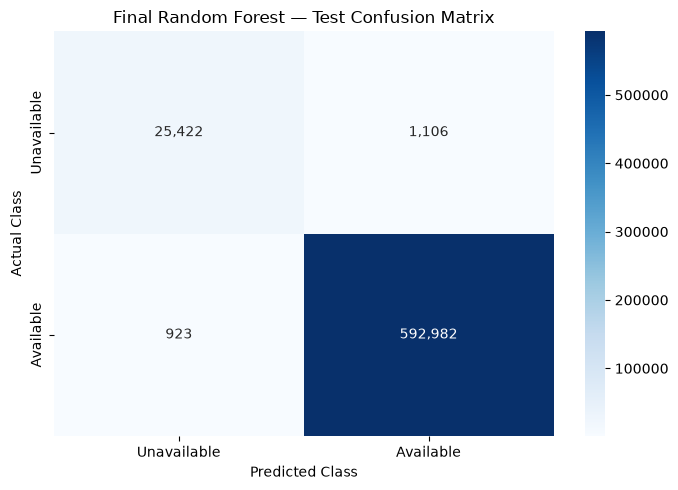

In [8]:
from sklearn.metrics import confusion_matrix

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

cm = confusion_matrix(
    test_predictions["y_true"],
    test_predictions["y_pred"],
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt=",d",
    cmap="Blues",
    xticklabels=["Unavailable", "Available"],
    yticklabels=["Unavailable", "Available"],
    ax=ax
)

ax.set_title("Final Random Forest — Test Confusion Matrix")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

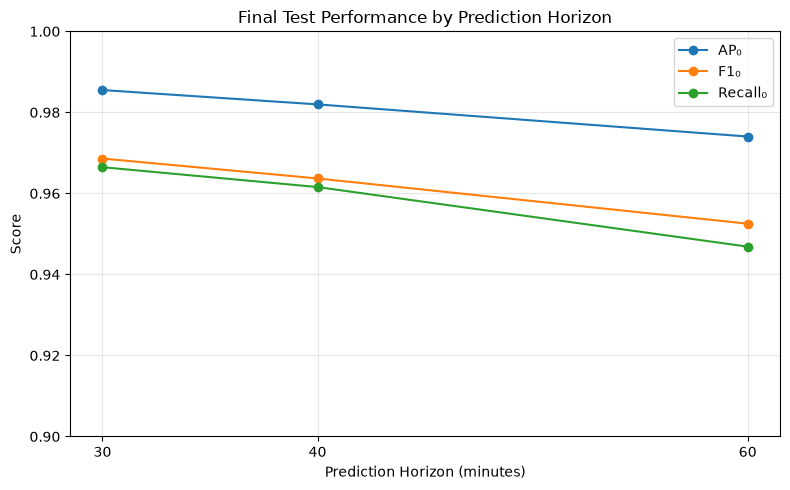

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))

for metric, label in [
    ("ap_0", "AP₀"),
    ("f1_0", "F1₀"),
    ("recall_0", "Recall₀")
]:
    ax.plot(
        test_by_horizon["prediction_horizon"],
        test_by_horizon[metric],
        marker="o",
        label=label
    )

ax.set_xticks([30, 40, 60])
ax.set_ylim(0.90, 1.0)
ax.set_xlabel("Prediction Horizon (minutes)")
ax.set_ylabel("Score")
ax.set_title("Final Test Performance by Prediction Horizon")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "final_test_horizon_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
test_tables = {
    "overall": test_overall,
    "by_horizon": test_by_horizon,
    "by_station_group": test_by_station,
    "validation_comparison": validation_test_comparison
}

for name, table in test_tables.items():
    path = TABLE_DIR / f"final_test_{name}.csv"

    table.to_csv(
        path,
        index=(name == "validation_comparison"),
        na_rep="N/A"
    )

    print("Saved:", path.relative_to(ROOT))

FINAL_PREDICTION_DIR = PREDICTION_DIR / "random_forest"

FINAL_PREDICTION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

prediction_path = (
    FINAL_PREDICTION_DIR
    / "initial_test_predictions.parquet"
)

test_predictions.to_parquet(
    prediction_path,
    index=False
)

print("Saved:", prediction_path.relative_to(ROOT))

Saved: outputs/tables/final_test_overall.csv
Saved: outputs/tables/final_test_by_horizon.csv
Saved: outputs/tables/final_test_by_station_group.csv
Saved: outputs/tables/final_test_validation_comparison.csv
Saved: outputs/predictions/random_forest/initial_test_predictions.parquet


## 8. Conclusion

Random Forest Initial was selected using validation
performance and evaluated on the held-out test dataset
without retraining or modifying its configuration.

The model achieved:

- Seen-station AP₀: 0.980596
- Overall accuracy: 99.673%
- Overall F1₀: 0.961625
- Overall recall₀: 0.958308
- Overall Brier score: 0.002871

The close agreement between validation and test
performance supports temporal generalization
for previously observed stations.

Performance decreases as the prediction horizon
increases, but remains strong across all three horizons.

Unseen-station generalization remains a limitation.
Both unseen test stations contain only available
observations, preventing a meaningful evaluation
of unavailable-class detection.

The selected model remains frozen and will be used
in the subsequent recommendation system development.